# Análise visual das imagens da Raiar

## 1. Extração de frames

O código importa as bibliotecas, localiza os dois vídeos da Raiar e extrai um frame a cada 2 segundos. Salva os quadros em pastas separadas por vídeo, mantém os arquivos já existentes e informa duração, taxa de quadros e quantidade de frames.


In [2]:
from pathlib import Path
import math
import sys

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle
from PIL import Image, ImageOps

try:
    import cv2
except ModuleNotFoundError as erro:
    raise ModuleNotFoundError(
        "OpenCV não está instalado neste kernel. Execute %pip install opencv-python "
        "em uma célula do notebook, reinicie o kernel e execute novamente."
    ) from erro

print(f"Python do kernel: {sys.executable}")

intervalo_segundos = 2
qualidade_jpeg = 95
if intervalo_segundos <= 0:
    raise ValueError("intervalo_segundos deve ser positivo")

nomes_videos = ("camera-raiar.mp4", "video-galinhas2.mp4")
candidatos = [
    Path.cwd() / "src" / "modelos_PIO",       # raiz do repositório
    Path.cwd() / "modelos_PIO",               # a partir de src/
    Path.cwd(),                               # a partir da pasta deste notebook
    Path.cwd().parent / "src" / "modelos_PIO",
]
pasta_raiar = next(
    (c / "midias" / "raiar" for c in candidatos
     if all((c / "midias" / "raiar" / Path(nome).stem / nome).is_file()
            for nome in nomes_videos)),
    None,
)
if pasta_raiar is None:
    raise FileNotFoundError(
        "Não encontrei os dois vídeos em src/modelos_PIO/midias/raiar."
    )

for nome_video in nomes_videos:
    video = pasta_raiar / Path(nome_video).stem / nome_video
    pasta_frames = video.parent / "frames"
    pasta_frames.mkdir(parents=True, exist_ok=True)
    captura = cv2.VideoCapture(str(video))
    if not captura.isOpened():
        raise OSError(f"Não foi possível abrir o vídeo: {video}")

    criados = 0
    existentes = 0
    try:
        fps = captura.get(cv2.CAP_PROP_FPS)
        total_quadros = int(captura.get(cv2.CAP_PROP_FRAME_COUNT))
        if fps <= 0 or total_quadros <= 0:
            raise ValueError(f"O vídeo não informou uma taxa de quadros ou duração válida: {video}")
        duracao_segundos = total_quadros / fps

        for segundo in range(0, math.ceil(duracao_segundos), intervalo_segundos):
            saida = pasta_frames / f"{video.stem}_t{segundo:04d}s.jpg"
            if saida.exists():
                existentes += 1
                continue
            captura.set(cv2.CAP_PROP_POS_FRAMES, round(segundo * fps))
            ok, quadro_bgr = captura.read()
            if not ok:
                raise OSError(f"Falha ao ler {video.name} em {segundo} segundos")
            if not cv2.imwrite(str(saida), quadro_bgr, [cv2.IMWRITE_JPEG_QUALITY, qualidade_jpeg]):
                raise OSError(f"Falha ao salvar o frame: {saida}")
            criados += 1
    finally:
        captura.release()

    print(f"Vídeo: {video.resolve()}")
    print(f"Duração: {duracao_segundos:.1f} s | taxa: {fps:.2f} quadros/s")
    print(f"Frames criados: {criados} | já existentes: {existentes}")
    print(f"Destino: {pasta_frames.resolve()}")

Python do kernel: C:\Users\Inteli\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe
Vídeo: C:\Users\Inteli\Documents\2026_02_Raiar\src\modelos_PIO\midias\raiar\camera-raiar\camera-raiar.mp4
Duração: 599.1 s | taxa: 15.00 quadros/s
Frames criados: 0 | já existentes: 300
Destino: C:\Users\Inteli\Documents\2026_02_Raiar\src\modelos_PIO\midias\raiar\camera-raiar\frames
Vídeo: C:\Users\Inteli\Documents\2026_02_Raiar\src\modelos_PIO\midias\raiar\video-galinhas2\video-galinhas2.mp4
Duração: 15.0 s | taxa: 14.95 quadros/s
Frames criados: 0 | já existentes: 8
Destino: C:\Users\Inteli\Documents\2026_02_Raiar\src\modelos_PIO\midias\raiar\video-galinhas2\frames


## 2. Seleção do vídeo

O código seleciona um dos dois vídeos, lista seus frames em ordem temporal e mostra a quantidade encontrada e os nomes do primeiro e do último arquivo.


In [3]:
# Escolha qual vídeo será mostrado nas próximas células.
nome_video_inspecao = "camera-raiar.mp4"  # ou "video-galinhas2.mp4"
if nome_video_inspecao not in nomes_videos:
    raise ValueError(f"Escolha um destes vídeos: {nomes_videos}")

pasta = pasta_raiar / Path(nome_video_inspecao).stem / "frames"
frames = sorted(pasta.glob(f"{Path(nome_video_inspecao).stem}_t????s.jpg"))
if not frames:
    raise FileNotFoundError(
        f"Nenhum frame de {nome_video_inspecao} encontrado em {pasta}. "
        "Execute primeiro a célula de extração."
    )

print(f"Vídeo selecionado: {nome_video_inspecao}")
print(f"Pasta: {pasta.resolve()}")
print(f"Frames encontrados: {len(frames)}")
print(f"Primeiro: {frames[0].name} | último: {frames[-1].name}")

Vídeo selecionado: camera-raiar.mp4
Pasta: C:\Users\Inteli\Documents\2026_02_Raiar\src\modelos_PIO\midias\raiar\camera-raiar\frames
Frames encontrados: 300
Primeiro: camera-raiar_t0000s.jpg | último: camera-raiar_t0598s.jpg


## 3. Visão geral do vídeo

O código escolhe até seis frames distribuídos ao longo do vídeo selecionado e os exibe em uma grade de imagens.


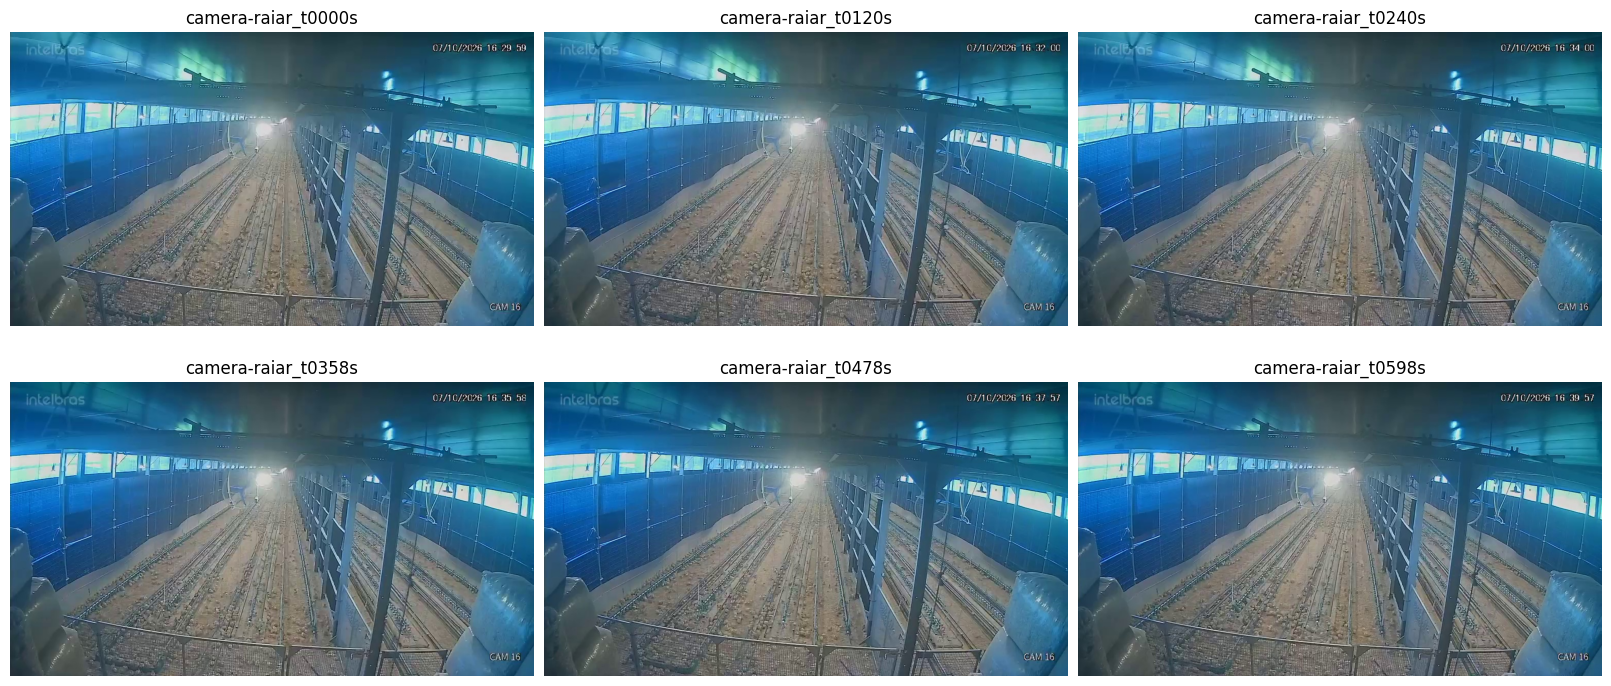

In [4]:
quantidade = min(6, len(frames))
indices = [round(i * (len(frames) - 1) / (quantidade - 1)) for i in range(quantidade)] if quantidade > 1 else [0]
fig, eixos = plt.subplots(2, 3, figsize=(16, 7), constrained_layout=True)
for eixo in eixos.flat:
    eixo.axis("off")
for eixo, indice_amostra in zip(eixos.flat, indices):
    with Image.open(frames[indice_amostra]) as origem:
        eixo.imshow(origem.convert("RGB"))
    eixo.set_title(frames[indice_amostra].stem)
plt.show()

## 4. Visualização de um frame

O código atualiza a lista de frames, seleciona o índice definido na célula, mostra as dimensões do quadro e exibe a imagem original.


Vídeo: camera-raiar.mp4 | frames encontrados: 300
camera-raiar_t0006s.jpg: 1024 × 576 pixels


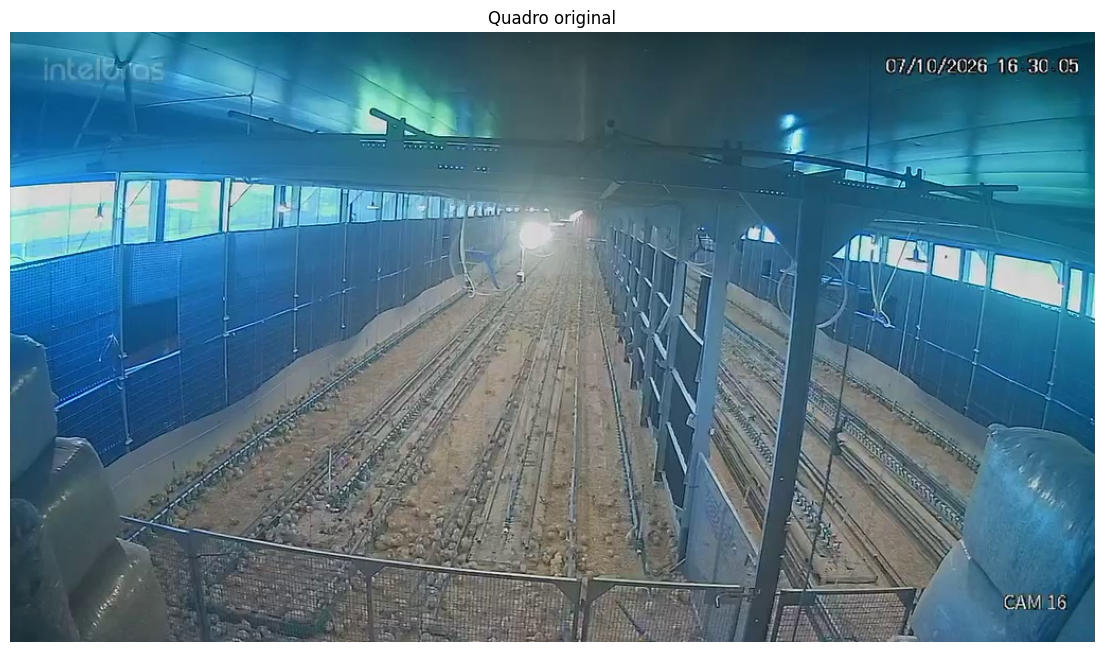

In [5]:
# Recarrega os frames do vídeo selecionado, mesmo que o kernel tenha uma lista antiga.
pasta = pasta_raiar / Path(nome_video_inspecao).stem / "frames"
frames = sorted(pasta.glob(f"{Path(nome_video_inspecao).stem}_t????s.jpg"))
print(f"Vídeo: {nome_video_inspecao} | frames encontrados: {len(frames)}")
if not frames:
    raise FileNotFoundError(
        f"Nenhum frame de {nome_video_inspecao}. Execute primeiro a célula de extração."
    )

indice = 3  # cerca de 6 segundos; altere para explorar
if not 0 <= indice < len(frames):
    raise IndexError(f"Escolha indice entre 0 e {len(frames) - 1}")
with Image.open(frames[indice]) as origem:
    quadro = origem.convert("RGB")
print(f"{frames[indice].name}: {quadro.width} × {quadro.height} pixels")
fig, eixo = plt.subplots(figsize=(14, 8))
eixo.imshow(quadro)
eixo.set_title("Quadro original")
eixo.axis("off")
plt.show()

## 5. Recorte de uma região

O código valida as coordenadas da região, recorta o quadro e exibe lado a lado a imagem original com a área demarcada e o recorte resultante.


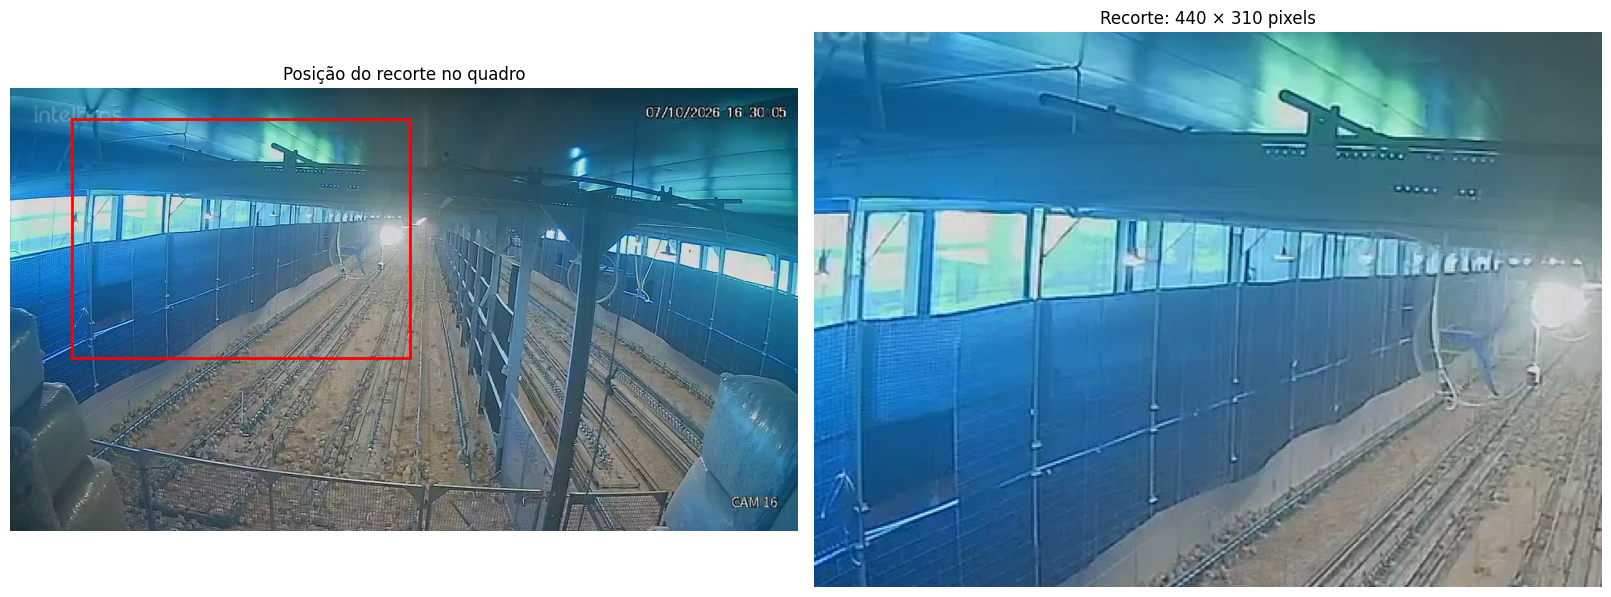

In [ ]:
regiao = (100, 80, 520, 350)  # ajuste para o vídeo selecionado
x_min, y_min, x_max, y_max = regiao
if not (0 <= x_min < x_max <= quadro.width and 0 <= y_min < y_max <= quadro.height):
    raise ValueError("A região deve estar dentro dos limites do quadro")
recorte = quadro.crop(regiao)
fig, (esquerda, direita) = plt.subplots(1, 2, figsize=(16, 6), constrained_layout=True)
esquerda.imshow(quadro)
esquerda.add_patch(Rectangle((x_min, y_min), x_max - x_min, y_max - y_min,
                             fill=False, edgecolor="red", linewidth=2))
esquerda.set_title("Posição do recorte no quadro")
direita.imshow(recorte)
direita.set_title(f"Recorte: {recorte.width} × {recorte.height} pixels")
for eixo in (esquerda, direita):
    eixo.axis("off")
plt.show()

## 6. Comparação na entrada de 640 × 640

O código ajusta o quadro inteiro e o recorte para 640 × 640 pixels, preservando a proporção com preenchimento nas bordas. Exibe as duas versões e informa o fator de escala de cada uma.


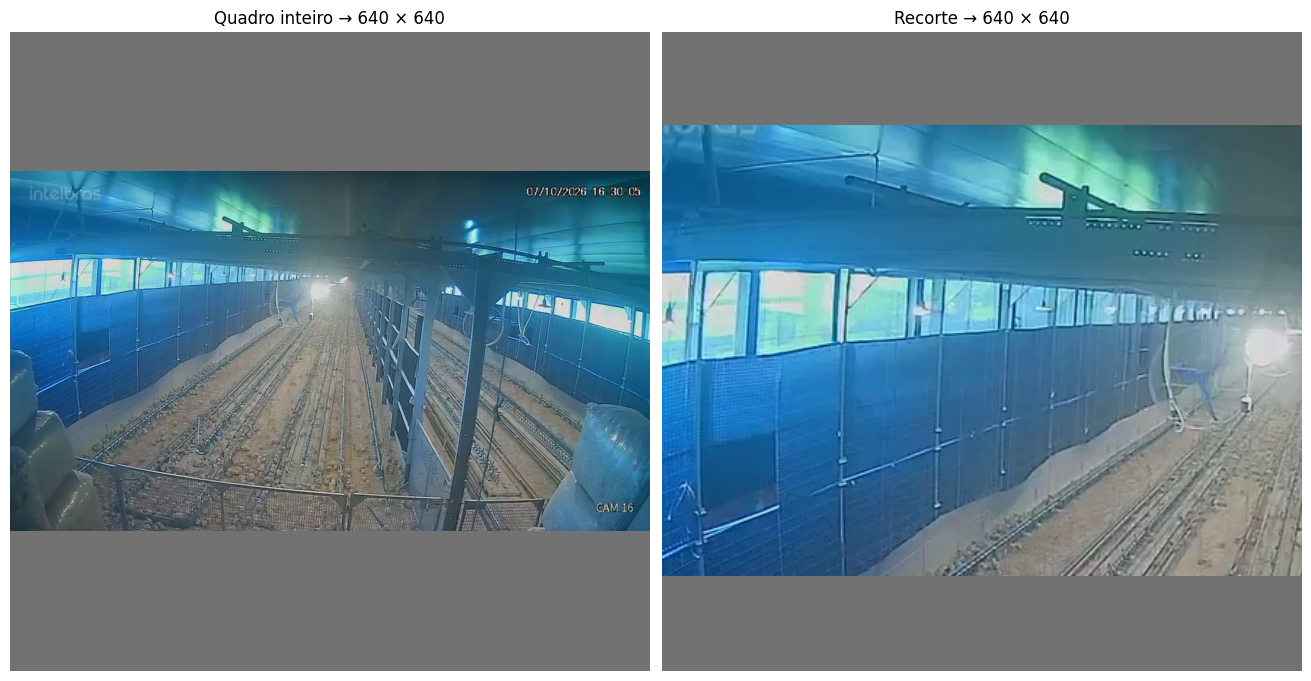

Fator de escala do quadro completo: 0.625
Fator de escala do recorte: 1.455


In [7]:
tamanho_entrada = (640, 640)
quadro_640 = ImageOps.pad(quadro, tamanho_entrada, method=Image.Resampling.BILINEAR,
                           color=(114, 114, 114))
recorte_640 = ImageOps.pad(recorte, tamanho_entrada, method=Image.Resampling.BILINEAR,
                            color=(114, 114, 114))
fig, (esquerda, direita) = plt.subplots(1, 2, figsize=(13, 7), constrained_layout=True)
esquerda.imshow(quadro_640)
esquerda.set_title("Quadro inteiro → 640 × 640")
direita.imshow(recorte_640)
direita.set_title("Recorte → 640 × 640")
for eixo in (esquerda, direita):
    eixo.axis("off")
plt.show()
print(f"Fator de escala do quadro completo: {min(640 / quadro.width, 640 / quadro.height):.3f}")
print(f"Fator de escala do recorte: {min(640 / recorte.width, 640 / recorte.height):.3f}")